In [38]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt


In [39]:
@dataclass
class SswPlotConfig:
    diag_dir: str
    ref_label: str = "ERA5"
    exp_keys: Sequence[str] = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")

    # plotting defaults
    plev_pa_series: Sequence[int] = (10000, 50000)  # 10 hPa, 50 hPa
    plev_pa_profile: Sequence[int] = (10000, 20000, 30000, 50000, 70000, 100000)  # for RMSE profile
    winter_months: Sequence[int] = (12, 1, 2)

    # file naming
    file_pattern: str = "ssw_monthly_{exp}_vs_{ref}.nc"

    # Save settings
    dpi: int = 200


class SswMonthlyPlotter:
    """
    Plotter for saved monthly stratospheric-vortex diagnostics produced by SswMonthlyAnalyzer.

    Expects per-experiment files like:
      figure_data/ssw_monthly/ssw_monthly_<EXP>_vs_ERA5.nc

    Each file should contain (names may vary slightly):
      - u_55_65N or u_60N, z_pcap, t_pcap (time, plev)
      - *_bias_<label> (time, plev)
      - *_rmse_winter_<label> (plev)  [or scalar per plev]
    """

    def __init__(self, cfg: SswPlotConfig):
        self.cfg = cfg
        self.dir = Path(cfg.diag_dir)

    # -------------------------
    # IO helpers
    # -------------------------
    def _path(self, exp: str) -> Path:
        return self.dir / self.cfg.file_pattern.format(exp=exp, ref=self.cfg.ref_label)

    def open(self, exp: str) -> xr.Dataset:
        f = self._path(exp)
        if not f.exists():
            raise FileNotFoundError(str(f))
        return xr.open_dataset(f)

    def open_all(self) -> Dict[str, xr.Dataset]:
        out = {}
        for exp in self.cfg.exp_keys:
            out[exp] = self.open(exp)
        return out

    # -------------------------
    # naming helpers
    # -------------------------
    def _u_index_name(self, ds: xr.Dataset) -> str:
        # Support either band-mean or single-lat versions
        if "u_55_65N" in ds.data_vars:
            return "u_55_65N"
        if "u_60N" in ds.data_vars:
            return "u_60N"
        # fallback: any variable starting with "u_" and containing "N"
        cands = [v for v in ds.data_vars if v.startswith("u_") and "N" in v]
        if cands:
            return cands[0]
        raise KeyError("Cannot find U index variable (expected u_55_65N or u_60N).")

    def _rmse_name(self, base: str, ds: xr.Dataset, season: str = "winter") -> str:
        """
        base in {"u_index","z_pcap","t_pcap"}.
        Stored name depends on analyzer label. We search robustly.
        """
        if base == "u_index":
            uvar = self._u_index_name(ds)
            prefix = uvar
        else:
            prefix = base

        # likely patterns:
        #   <prefix>_rmse_winter_<label>
        #   <prefix>_rmse_all_<label>
        # label might be "ERA5" or "vs_ref" depending on your run.
        # We'll search for best match containing rmse and season.
        season_key = f"rmse_{season}"
        cands = [v for v in ds.data_vars if v.startswith(prefix) and "rmse" in v and season_key in v]
        if cands:
            return cands[0]

        # try any rmse with season
        cands = [v for v in ds.data_vars if v.startswith(prefix) and "rmse" in v and season in v]
        if cands:
            return cands[0]

        # fallback to all-month rmse
        cands = [v for v in ds.data_vars if v.startswith(prefix) and "rmse_all" in v]
        if cands:
            return cands[0]

        raise KeyError(f"Cannot find RMSE variable for {prefix} with season={season}.")

    def _bias_name(self, base: str, ds: xr.Dataset) -> str:
        if base == "u_index":
            uvar = self._u_index_name(ds)
            prefix = uvar
        else:
            prefix = base
        cands = [v for v in ds.data_vars if v.startswith(prefix) and "_bias_" in v]
        if cands:
            return cands[0]
        raise KeyError(f"Cannot find bias variable for {prefix}.")

    # -------------------------
    # selection helpers
    # -------------------------
    @staticmethod
    def _sel_plev(da: xr.DataArray, p_pa: int) -> xr.DataArray:
        return da.sel(plev=p_pa, method="nearest")

    @staticmethod
    def _plev_label(p_pa: int) -> str:
        # Pa -> hPa
        return f"{int(round(p_pa / 100.0))} hPa"
        
    def _time_to_plot_axis(self, time_values):
        """
        Convert cftime/numpy datetime time array into:
          x: float array (0..N-1)
          labels: list[str] like YYYY-MM
        """
        t = np.asarray(time_values)
        n = len(t)
        x = np.arange(n, dtype=float)

        labels = []
        for tt in t:
            # cftime
            if hasattr(tt, "year") and hasattr(tt, "month"):
                labels.append(f"{int(tt.year):04d}-{int(tt.month):02d}")
            else:
                # numpy datetime64
                s = np.datetime_as_string(tt, unit="M")  # "YYYY-MM"
                labels.append(s)
        return x, labels

    def _set_month_ticks(self, ax, x, labels, step=3):
        """
        Put ticks every `step` months with YYYY-MM labels.
        """
        if len(x) == 0:
            return
        idx = np.arange(0, len(x), step, dtype=int)
        ax.set_xticks(x[idx])
        ax.set_xticklabels([labels[i] for i in idx], rotation=45, ha="right")

    # -------------------------
    # Figure 1: time series
    # -------------------------
    def plot_timeseries(
        self,
        exp_keys: Optional[Sequence[str]] = None,
        plev_pa: Optional[Sequence[int]] = None,
        out_png: Optional[str | Path] = None,
        show: bool = True,
        step: int = 3
    ):
        exp_keys = exp_keys or self.cfg.exp_keys
        plev_pa = plev_pa or self.cfg.plev_pa_series

        # Use CTRL file to discover the U index name (consistent across saved files)
        ds0 = self.open(exp_keys[0])
        uvar = self._u_index_name(ds0)

        # variables to plot
        vars_to_plot = [
            ("U index", uvar),
            ("Z polar cap", "z_pcap"),
            ("T polar cap", "t_pcap"),
        ]

        nrow = len(vars_to_plot)
        ncol = len(plev_pa)

        fig, axes = plt.subplots(nrow, ncol, figsize=(4.8 * ncol, 2.8 * nrow), sharex=True)
        if nrow == 1 and ncol == 1:
            axes = np.array([[axes]])
        elif nrow == 1:
            axes = np.array([axes])
        elif ncol == 1:
            axes = axes[:, None]

        for j, p in enumerate(plev_pa):
            for i, (title, vname) in enumerate(vars_to_plot):
                ax = axes[i, j]
                for exp in exp_keys:
                    ds = self.open(exp)
                    da = self._sel_plev(ds[vname], p)
                    x, labels = self._time_to_plot_axis(ds["time"].values)
                    ax.plot(x, da.values, label=exp)
                    if i == nrow - 1:
                        self._set_month_ticks(ax, x, labels, step=step)  # every 3 months
    
                ax.set_title(f"{title} @ {self._plev_label(p)}")
                ax.grid(True, alpha=0.3)
                if i == nrow - 1:
                    ax.set_xlabel("Month")
                if j == 0:
                    ax.set_ylabel(title)

        # Single legend outside
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=min(len(exp_keys), 6), frameon=False)
        fig.tight_layout(rect=[0, 0, 1, 0.92])

        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=self.cfg.dpi, bbox_inches="tight")

        if show:
            plt.show()
        else:
            plt.close(fig)

        return fig

    # -------------------------
    # Figure 2: winter RMSE vertical profiles
    # -------------------------
    def plot_rmse_profiles(
        self,
        exp_keys: Optional[Sequence[str]] = None,
        plev_pa: Optional[Sequence[int]] = None,
        out_png: Optional[str | Path] = None,
        show: bool = True,
    ):
        exp_keys = exp_keys or self.cfg.exp_keys
        plev_pa = list(plev_pa or self.cfg.plev_pa_profile)

        # Open first dataset to discover names
        ds0 = self.open(exp_keys[0])
        u_rmse = self._rmse_name("u_index", ds0, season="winter")
        z_rmse = self._rmse_name("z_pcap", ds0, season="winter")
        t_rmse = self._rmse_name("t_pcap", ds0, season="winter")

        metrics = [
            ("U index RMSE (winter)", u_rmse, "u_index"),
            ("Z polar cap RMSE (winter)", z_rmse, "z_pcap"),
            ("T polar cap RMSE (winter)", t_rmse, "t_pcap"),
        ]

        fig, axes = plt.subplots(1, 3, figsize=(12.5, 5.2), sharey=True)

        for ax, (title, rmse_var, _) in zip(axes, metrics):
            for exp in exp_keys:
                ds = self.open(exp)
                da = ds[rmse_var]
                # ensure we have plev dimension; some might be scalar if collapsed
                if "plev" in da.dims:
                    prof = da.sel(plev=plev_pa, method="nearest")
                    ax.plot(prof.values, prof["plev"].values / 100.0, marker="o", label=exp)
                else:
                    # scalar RMSE (shouldn't happen with current analyzer, but keep safe)
                    ax.scatter([float(da.values)], [np.nan], label=exp)

            ax.set_title(title)
            ax.grid(True, alpha=0.3)
            ax.set_xlabel("RMSE")

        axes[0].set_ylabel("Pressure (hPa)")
        axes[0].invert_yaxis()

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=min(len(exp_keys), 6), frameon=False)
        fig.tight_layout(rect=[0, 0, 1, 0.92])

        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=self.cfg.dpi, bbox_inches="tight")

        if show:
            plt.show()
        else:
            plt.close(fig)

        return fig

    # -------------------------
    # Figure 3: attribution bars (difference-of-differences style)
    # -------------------------
    def plot_attribution_bars(
        self,
        plev_pa: int = 10000,
        out_png: Optional[str | Path] = None,
        show: bool = True,
    ):
        """
        Plot RMSE deltas at a single pressure level to isolate ATM vs LND effects.

        Uses winter RMSE of U index by default (you can change metric below).
        """
        # choose metric for attribution (most intuitive is U index at 10 hPa)
        ds0 = self.open(self.cfg.exp_keys[0])
        u_rmse = self._rmse_name("u_index", ds0, season="winter")

        # helper to get RMSE at level
        def rmse_at(exp: str) -> float:
            ds = self.open(exp)
            da = ds[u_rmse]
            if "plev" in da.dims:
                return float(self._sel_plev(da, plev_pa).values)
            return float(da.values)

        # define comparisons (edit freely)
        comparisons = [
            # ATM effects (land fixed = Arbitrary)
            ("ATM: ERA5 (ERA5BL - CTRL)", rmse_at("ERA5BL") - rmse_at("CTRL")),
            ("ATM: DART (DARTBL - CTRL)", rmse_at("DARTBL") - rmse_at("CTRL")),
            # LND effects under fixed ATM
            ("LND: DART | ATM=ERA5 (ERA5DL - ERA5BL)", rmse_at("ERA5DL") - rmse_at("ERA5BL")),
            ("LND: ERA5-forced | ATM=ERA5 (ERA5OP - ERA5BL)", rmse_at("ERA5OP") - rmse_at("ERA5BL")),
            ("LND: DART | ATM=DART (DARTOP - DARTBL)", rmse_at("DARTOP") - rmse_at("DARTBL")),
            ("LND: ERA5-forced | ATM=DART (DARTAE - DARTBL)", rmse_at("DARTAE") - rmse_at("DARTBL")),
            # Interaction ("synergy") for DART land only (identifiable with your design)
            ("INT: DART land × DART atm", (rmse_at("DARTOP") - rmse_at("DARTBL")) - (rmse_at("DARTBA") - rmse_at("CTRL"))),
            ("INT: DART land × ERA5 atm", (rmse_at("ERA5DL") - rmse_at("ERA5BL")) - (rmse_at("DARTBA") - rmse_at("CTRL"))),
            # Full strategy comparison (changes both ATM and LND)
            ("STRAT: DARTOP - ERA5OP", rmse_at("DARTOP") - rmse_at("ERA5OP")),
            # Optional: atmosphere-only strategy comparison (land fixed = Arbitrary)
            ("STRAT: DARTBL - ERA5BL", rmse_at("DARTBL") - rmse_at("ERA5BL")),
        ]


        labels = [c[0] for c in comparisons]
        vals = np.array([c[1] for c in comparisons], dtype=float)

        fig, ax = plt.subplots(1, 1, figsize=(11, 3.8))
        ax.bar(np.arange(len(vals)), vals)
        ax.axhline(0.0, linewidth=1.0)
        ax.set_xticks(np.arange(len(vals)))
        ax.set_xticklabels(labels, rotation=30, ha="right")
        ax.set_ylabel(f"Δ winter RMSE ({self._plev_label(plev_pa)})")
        ax.set_title("Initialization attribution (negative = improvement vs baseline)")
        ax.grid(True, axis="y", alpha=0.3)
        fig.tight_layout()

        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=self.cfg.dpi, bbox_inches="tight")

        if show:
            plt.show()
        else:
            plt.close(fig)

        return fig
        
    def plot_bias_and_running_rmse_timeseries(
        self,
        exp_keys: Optional[Sequence[str]] = None,
        plev_pa: Sequence[int] = (10000, 100000),   # 10 hPa + 100 hPa default (good for SSW + coupling)
        label: Optional[str] = None,                # default uses cfg.ref_label
        window: int = 3,                            # 3-month running RMSE; set None/1 to skip
        out_png: Optional[str | Path] = None,
        show: bool = True,
    ):
        """
        Plot (i) bias time series and (ii) running RMSE time series for ALL THREE diagnostics:
          - U index (u_55_65N or u_60N)
          - z_pcap
          - t_pcap
    
        Uses the saved bias variables in each ssw_monthly_<EXP>_vs_<REF>.nc file.
        X-axis is lead-month index (0..N-1) with YYYY-MM tick labels.
        """
        exp_keys = exp_keys or self.cfg.exp_keys
        label = label or self.cfg.ref_label
    
        # open one ds to detect U index name
        ds0 = self.open(exp_keys[0])
        uvar = self._u_index_name(ds0)
    
        # bias variable names in saved files
        bias_vars = [
            ("U index bias", f"{uvar}_bias_{label}"),
            ("Z polar-cap bias", f"z_pcap_bias_{label}"),
            ("T polar-cap bias", f"t_pcap_bias_{label}"),
        ]
    
        nrow = len(bias_vars)
        ncol = len(plev_pa)
    
        fig, axes = plt.subplots(
            nrow, ncol,
            figsize=(5.2 * ncol, 2.9 * nrow),
            sharex=True,
            sharey=False
        )
        if nrow == 1 and ncol == 1:
            axes = np.array([[axes]])
        elif nrow == 1:
            axes = np.array([axes])
        elif ncol == 1:
            axes = axes[:, None]
    
        # use first experiment time for x + labels
        x, tick_labels = self._time_to_plot_axis(ds0["time"].values)
    
        for j, p in enumerate(plev_pa):
            for i, (title, vname) in enumerate(bias_vars):
                ax = axes[i, j]
    
                for exp in exp_keys:
                    ds = self.open(exp)
                    if vname not in ds:
                        raise KeyError(
                            f"{exp}: missing '{vname}'. Available bias vars: "
                            f"{[vv for vv in ds.data_vars if '_bias_' in vv][:10]}"
                        )
    
                    da = ds[vname]
                    if "plev" in da.dims:
                        da = self._sel_plev(da, p)
    
                    # Bias (error) curve
                    ax.plot(x, da.values, label=exp)
    
                    # Optional running RMSE overlay (thicker)
                    if window is not None and int(window) > 1:
                        # running mean of squared error, then sqrt
                        e2 = xr.DataArray(da.values**2, dims=("t",))
                        rmse_run = np.sqrt(e2.rolling(t=window, center=True, min_periods=window).mean())
                        ax.plot(x, rmse_run.values, linewidth=2.8, alpha=0.65)
    
                ax.axhline(0.0, linewidth=0.8, alpha=0.6)
                ax.grid(True, alpha=0.3)
    
                ax.set_title(f"{title} @ {self._plev_label(p)}")
                if j == 0:
                    ax.set_ylabel("Error vs ERA5")
    
                # ticks only on bottom row
                if i == nrow - 1:
                    self._set_month_ticks(ax, x, tick_labels, step=3)
                    ax.set_xlabel("Lead month")
    
        # Legend once
        handles, labels_ = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels_, loc="upper center", ncol=min(len(exp_keys), 6), frameon=False)
        fig.tight_layout(rect=[0, 0, 1, 0.92])
    
        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=self.cfg.dpi, bbox_inches="tight")
    
        if show:
            plt.show()
        else:
            plt.close(fig)
    
        return fig
        
    def plot_earlylead_rmse_attribution(
        self,
        level_pa: int = 10000,              # 10 hPa default for SSW
        lead_months: int = 3,               # 3 or 6
        use_var: str = "u",                 # "u" or "z" or "t"
        out_png: str | Path | None = None,
        show: bool = True,
    ):
        """
        Early-lead RMSE attribution bars using bias time series from saved *_vs_ERA5.nc.
    
        lead_months counts from initialization: months [0, lead_months-1].
        use_var:
          - "u": U index (55–65N band if present, else 60N)
          - "z": z_pcap
          - "t": t_pcap
        """
        import matplotlib.pyplot as plt
        import numpy as np
    
        ref = self.cfg.ref_label  # "ERA5"
    
        # determine U index variable name robustly
        ds0 = self.open(self.cfg.exp_keys[0])
        uvar = self._u_index_name(ds0)
    
        if use_var == "u":
            vbase = uvar
        elif use_var == "z":
            vbase = "z_pcap"
        elif use_var == "t":
            vbase = "t_pcap"
        else:
            raise ValueError("use_var must be 'u', 'z', or 't'.")
    
        vname = f"{vbase}_bias_{ref}"
    
        def early_rmse(exp_key: str) -> float:
            ds = self.open(exp_key)
            if vname not in ds:
                raise KeyError(f"{exp_key}: missing {vname}")
            da = ds[vname]
            if "plev" in da.dims:
                da = self._sel_plev(da, level_pa)
            # early-lead slice
            arr = da.isel(time=slice(0, lead_months)).values.astype(float)
            return float(np.sqrt(np.nanmean(arr**2)))
    
        # ---- attribution pairs (reviewer-proof) ----
        # These map to your Table 1 logic.
        bars = [
            # ATM effects (land fixed = arbitrary)
            ("ATM: ERA5BL - CTRL", early_rmse("ERA5BL") - early_rmse("CTRL")),
            ("ATM: DARTBL - CTRL", early_rmse("DARTBL") - early_rmse("CTRL")),
    
            # LND effects (single-component swaps)
            ("LND: DARTBA - CTRL", early_rmse("DARTBA") - early_rmse("CTRL")),
            ("LND: ERA5DL - ERA5BL", early_rmse("ERA5DL") - early_rmse("ERA5BL")),
            ("LND: DARTAE - DARTBL", early_rmse("DARTAE") - early_rmse("DARTBL")),
    
            # Coupled strategy comparisons
            ("COUP: ERA5OP - ERA5BL", early_rmse("ERA5OP") - early_rmse("ERA5BL")),
            ("COUP: DARTOP - DARTBL", early_rmse("DARTOP") - early_rmse("DARTBL")),
            ("STRAT: DARTOP - ERA5OP", early_rmse("DARTOP") - early_rmse("ERA5OP")),
        ]
    
        names = [b[0] for b in bars]
        vals  = np.array([b[1] for b in bars], dtype=float)
    
        fig, ax = plt.subplots(figsize=(12.5, 3.8))
        ax.bar(np.arange(len(vals)), vals)
        ax.axhline(0, linewidth=1.0)
    
        ax.set_title(f"Early-lead RMSE attribution ({use_var.upper()} bias vs {ref}, "
                     f"{self._plev_label(level_pa)}, months 0–{lead_months-1})")
        ax.set_ylabel("Δ RMSE (negative = improvement)")
        ax.set_xticks(np.arange(len(vals)))
        ax.set_xticklabels(names, rotation=25, ha="right")
        ax.grid(True, axis="y", alpha=0.3)
        fig.tight_layout()
    
        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=self.cfg.dpi, bbox_inches="tight")
    
        if show:
            plt.show()
        else:
            plt.close(fig)
    
        return fig


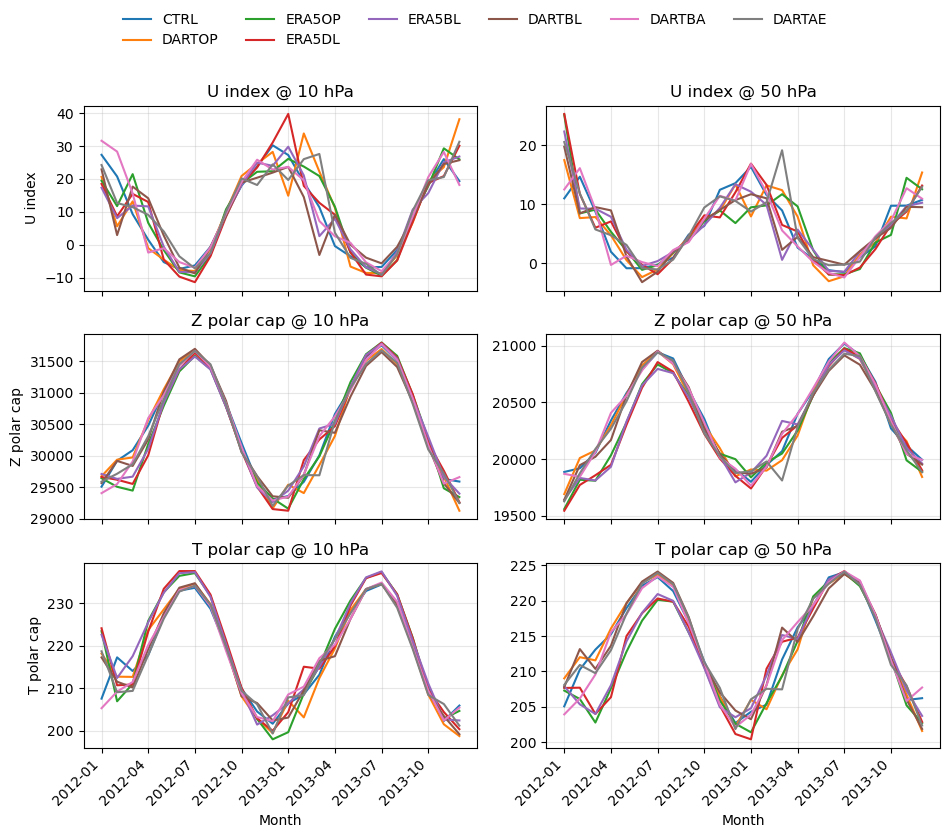

DONE


In [41]:
if __name__ == "__main__":
    from pathlib import Path

    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir  = Path(work_dir) / "figure_data" / "ssw_monthly"

    period  = "2012-2013"
    ref_exp = "ERA5"
    exp_list = ["CTRL", "DARTOP", "ERA5OP", "ERA5DL","ERA5BL", "DARTBL", "DARTBA", "DARTAE"]

    # --- plotting styles (kept for future extension / manual plots)
    style_map = {
        "ERA5":   dict(color="k",          linestyle="-",  linewidth=2.8, zorder=6),
        "CTRL":   dict(color="0.55",       linestyle="-",  linewidth=2.3, zorder=5),

        # DA atmosphere (red)
        "DARTOP": dict(color="tab:red",    linestyle="-",  linewidth=2.6, zorder=6),
        "ERA5OP": dict(color="tab:red",    linestyle="--", linewidth=2.6, zorder=6),

        # ERA5-* family (blue)
        "ERA5DL": dict(color="tab:blue",   linestyle="-",  linewidth=1.8, zorder=4),
        "ERA5BL": dict(color="tab:blue",   linestyle=":",  linewidth=1.8, zorder=4),

        # DART-* family (purple)
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.8, zorder=4),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.8, zorder=4),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=1.8, zorder=4),
    }

    out_dir = Path("./").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------------------
    # Configure and create SSW plotter
    # ------------------------------------------------------------------
    plot_cfg = SswPlotConfig(
        diag_dir=str(ssw_dir),
        ref_label=ref_exp,
        exp_keys=exp_list,
        plev_pa_series=(1000, 5000),                  # 10 & 50 hPa
        plev_pa_profile=(10000, 20000, 30000, 50000,70000, 100000), # RMSE profiles
    )

    plotter = SswMonthlyPlotter(plot_cfg)

    # ------------------------------------------------------------------
    # Figure 1: Monthly time series (U, Zpc, Tpc)
    # ------------------------------------------------------------------
    plotter.plot_timeseries(
        exp_keys=exp_list,
        out_png=out_dir / f"ssw_{period}_timeseries.png",
        show=True,
    )
    print("DONE")

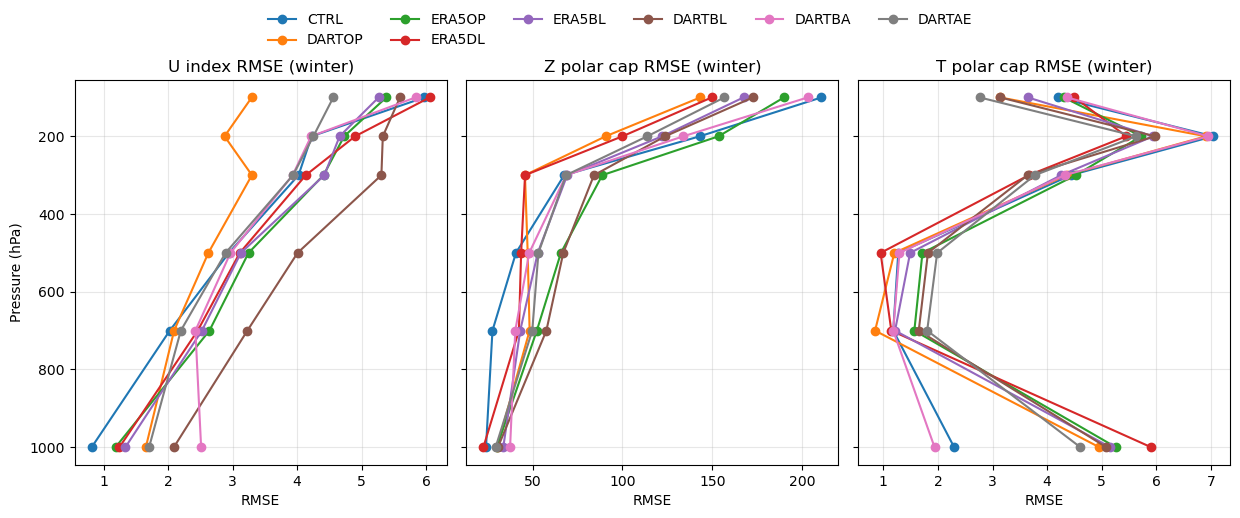

DONE


In [34]:
if __name__ == "__main__":
    from pathlib import Path

    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir  = Path(work_dir) / "figure_data" / "ssw_monthly"

    period  = "2012-2013"
    ref_exp = "ERA5"
    exp_list = [
        "CTRL", "DARTOP", "ERA5OP", "ERA5DL",
        "ERA5BL", "DARTBL", "DARTBA", "DARTAE",
    ]

    # --- plotting styles (kept for future extension / manual plots)
    style_map = {
        "ERA5":   dict(color="k",          linestyle="-",  linewidth=2.8, zorder=6),
        "CTRL":   dict(color="0.55",       linestyle="-",  linewidth=2.3, zorder=5),

        # DA atmosphere (red)
        "DARTOP": dict(color="tab:red",    linestyle="-",  linewidth=2.6, zorder=6),
        "ERA5OP": dict(color="tab:red",    linestyle="--", linewidth=2.6, zorder=6),

        # ERA5-* family (blue)
        "ERA5DL": dict(color="tab:blue",   linestyle="-",  linewidth=1.8, zorder=4),
        "ERA5BL": dict(color="tab:blue",   linestyle=":",  linewidth=1.8, zorder=4),

        # DART-* family (purple)
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.8, zorder=4),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.8, zorder=4),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=1.8, zorder=4),
    }

    out_dir = Path("./").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------------------
    # Configure and create SSW plotter
    # ------------------------------------------------------------------
    plot_cfg = SswPlotConfig(
        diag_dir=str(ssw_dir),
        ref_label=ref_exp,
        exp_keys=exp_list,
        plev_pa_series=(10000, 50000),                  # 10 & 50 hPa
        plev_pa_profile=(10000, 20000, 30000, 50000,
                          70000, 100000),               # RMSE profiles
    )

    plotter = SswMonthlyPlotter(plot_cfg)

    # ------------------------------------------------------------------
    # Figure 2: Winter RMSE vertical profiles
    # ------------------------------------------------------------------
    plotter.plot_rmse_profiles(
        exp_keys=exp_list,
        out_png=out_dir / f"ssw_{period}_rmse_profiles.png",
        show=True,
    )


    print("DONE")

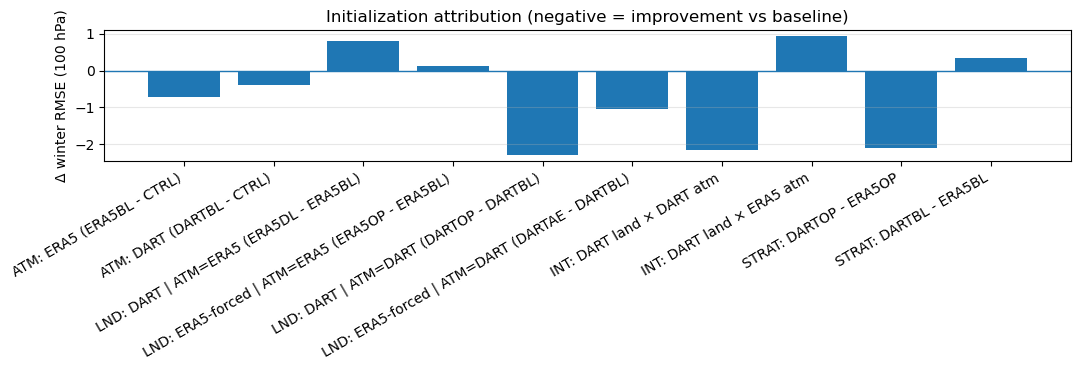

DONE


In [35]:
if __name__ == "__main__":
    from pathlib import Path

    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir  = Path(work_dir) / "figure_data" / "ssw_monthly"

    period  = "2012-2013"
    ref_exp = "ERA5"
    exp_list = [
        "CTRL", "DARTOP", "ERA5OP", "ERA5DL",
        "ERA5BL", "DARTBL", "DARTBA", "DARTAE",
    ]

    # --- plotting styles (kept for future extension / manual plots)
    style_map = {
        "ERA5":   dict(color="k",          linestyle="-",  linewidth=2.8, zorder=6),
        "CTRL":   dict(color="0.55",       linestyle="-",  linewidth=2.3, zorder=5),

        # DA atmosphere (red)
        "DARTOP": dict(color="tab:red",    linestyle="-",  linewidth=2.6, zorder=6),
        "ERA5OP": dict(color="tab:red",    linestyle="--", linewidth=2.6, zorder=6),

        # ERA5-* family (blue)
        "ERA5DL": dict(color="tab:blue",   linestyle="-",  linewidth=1.8, zorder=4),
        "ERA5BL": dict(color="tab:blue",   linestyle=":",  linewidth=1.8, zorder=4),

        # DART-* family (purple)
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.8, zorder=4),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.8, zorder=4),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=1.8, zorder=4),
    }

    out_dir = Path("./").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------------------
    # Configure and create SSW plotter
    # ------------------------------------------------------------------
    plot_cfg = SswPlotConfig(
        diag_dir=str(ssw_dir),
        ref_label=ref_exp,
        exp_keys=exp_list,
        plev_pa_series=(10000, 50000),                  # 10 & 50 hPa
        plev_pa_profile=(10000, 20000, 30000, 50000,
                          70000, 100000),               # RMSE profiles
    )

    plotter = SswMonthlyPlotter(plot_cfg)

    # ------------------------------------------------------------------
    # Figure 3: Initialization attribution bars (10 hPa)
    # ------------------------------------------------------------------
    plotter.plot_attribution_bars(
        plev_pa=10000,
        out_png=out_dir / f"ssw_{period}_attribution_10hPa.png",
        show=True,
    )

    print("DONE")

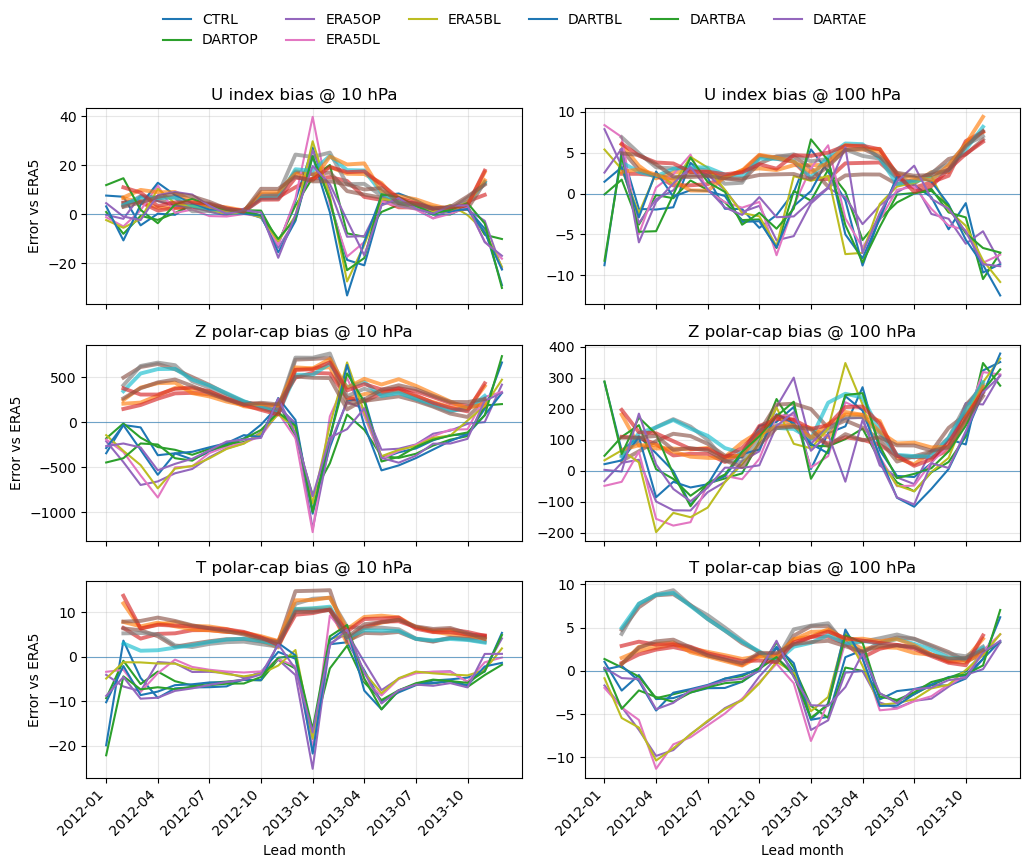

DONE


In [36]:
if __name__ == "__main__":
    from pathlib import Path

    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir  = Path(work_dir) / "figure_data" / "ssw_monthly"

    period  = "2012-2013"
    ref_exp = "ERA5"
    exp_list = [
        "CTRL", "DARTOP", "ERA5OP", "ERA5DL",
        "ERA5BL", "DARTBL", "DARTBA", "DARTAE",
    ]

    # --- plotting styles (kept for future extension / manual plots)
    style_map = {
        "ERA5":   dict(color="k",          linestyle="-",  linewidth=2.8, zorder=6),
        "CTRL":   dict(color="0.55",       linestyle="-",  linewidth=2.3, zorder=5),

        # DA atmosphere (red)
        "DARTOP": dict(color="tab:red",    linestyle="-",  linewidth=2.6, zorder=6),
        "ERA5OP": dict(color="tab:red",    linestyle="--", linewidth=2.6, zorder=6),

        # ERA5-* family (blue)
        "ERA5DL": dict(color="tab:blue",   linestyle="-",  linewidth=1.8, zorder=4),
        "ERA5BL": dict(color="tab:blue",   linestyle=":",  linewidth=1.8, zorder=4),

        # DART-* family (purple)
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.8, zorder=4),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.8, zorder=4),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=1.8, zorder=4),
    }

    out_dir = Path("./").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------------------
    # Configure and create SSW plotter
    # ------------------------------------------------------------------
    plot_cfg = SswPlotConfig(
        diag_dir=str(ssw_dir),
        ref_label=ref_exp,
        exp_keys=exp_list,
        plev_pa_series=(10000, 50000),                  # 10 & 50 hPa
        plev_pa_profile=(10000, 20000, 30000, 50000,
                          70000, 100000),               # RMSE profiles
    )

    plotter = SswMonthlyPlotter(plot_cfg)

    # ------------------------------------------------------------------
    # Figure 4: Initialization attribution bars (10 hPa)
    # ------------------------------------------------------------------
    plotter.plot_bias_and_running_rmse_timeseries(
        exp_keys=exp_list,  # or all
        plev_pa=(1000, 10000),   # 10 hPa and 100 hPa
        window=3,                  # 3-month running RMSE overlay
        out_png=out_dir / f"ssw_{period}_bias_runningRMSE_10_100hPa.png",
        show=True,
    )

    print("DONE")

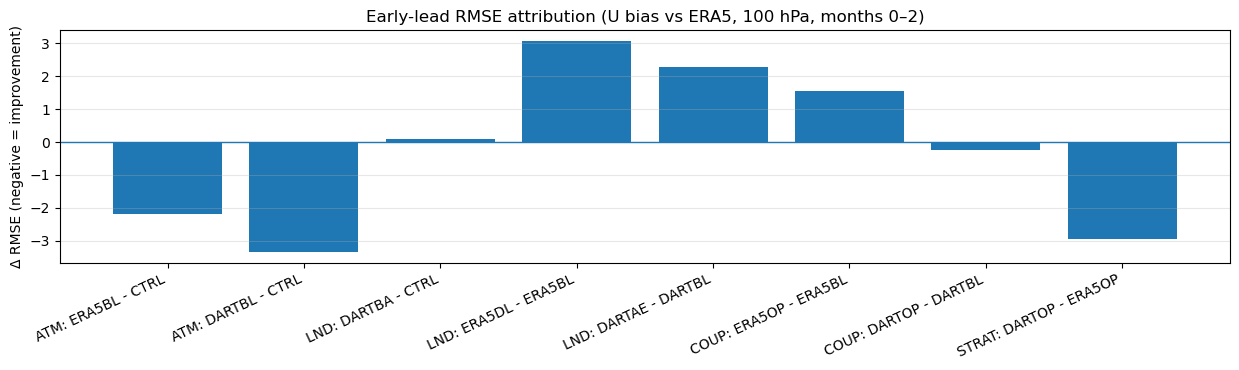

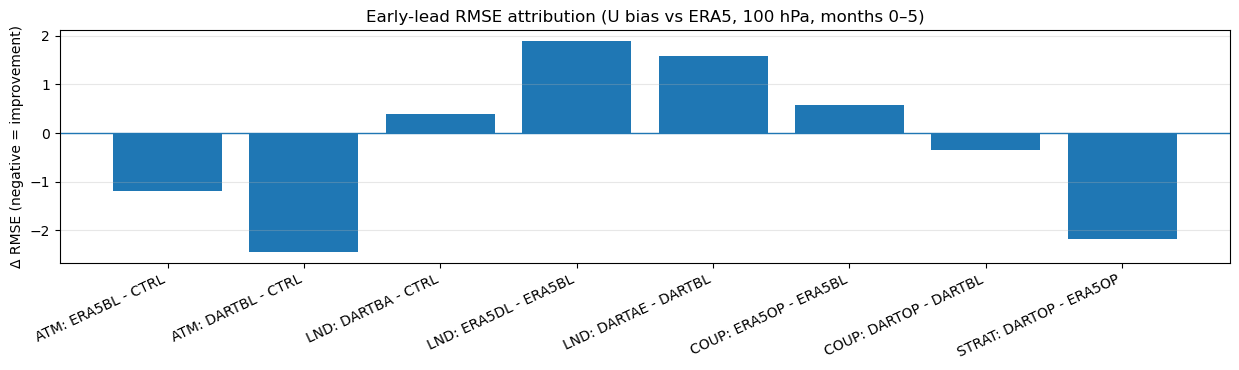

DONE


In [37]:
if __name__ == "__main__":
    from pathlib import Path

    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir  = Path(work_dir) / "figure_data" / "ssw_monthly"

    period  = "2012-2013"
    ref_exp = "ERA5"
    exp_list = [
        "CTRL", "DARTOP", "ERA5OP", "ERA5DL",
        "ERA5BL", "DARTBL", "DARTBA", "DARTAE",
    ]

    # --- plotting styles (kept for future extension / manual plots)
    style_map = {
        "ERA5":   dict(color="k",          linestyle="-",  linewidth=2.8, zorder=6),
        "CTRL":   dict(color="0.55",       linestyle="-",  linewidth=2.3, zorder=5),

        # DA atmosphere (red)
        "DARTOP": dict(color="tab:red",    linestyle="-",  linewidth=2.6, zorder=6),
        "ERA5OP": dict(color="tab:red",    linestyle="--", linewidth=2.6, zorder=6),

        # ERA5-* family (blue)
        "ERA5DL": dict(color="tab:blue",   linestyle="-",  linewidth=1.8, zorder=4),
        "ERA5BL": dict(color="tab:blue",   linestyle=":",  linewidth=1.8, zorder=4),

        # DART-* family (purple)
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.8, zorder=4),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.8, zorder=4),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=1.8, zorder=4),
    }

    out_dir = Path("./").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------------------
    # Configure and create SSW plotter
    # ------------------------------------------------------------------
    plot_cfg = SswPlotConfig(
        diag_dir=str(ssw_dir),
        ref_label=ref_exp,
        exp_keys=exp_list,
        plev_pa_series=(10000, 50000),                  # 10 & 50 hPa
        plev_pa_profile=(10000, 20000, 30000, 50000,
                          70000, 100000),               # RMSE profiles
    )

    plotter = SswMonthlyPlotter(plot_cfg)

    # ------------------------------------------------------------------
    # Figure 4: Initialization attribution bars (10 hPa)
    # ------------------------------------------------------------------
    plotter.plot_earlylead_rmse_attribution(
        level_pa=10000,
        lead_months=3,
        use_var="u",
        out_png=out_dir / f"ssw_{period}_attr_U10_month0-2.png",
        show=True,
    )
    plotter.plot_earlylead_rmse_attribution(
        level_pa=10000,
        lead_months=6,
        use_var="u",
        out_png=out_dir / f"ssw_{period}_attr_U10_month0-2.png",
        show=True,
    )
    print("DONE")